# FlightOps ML — Model Benchmarks & Diagnostic Evaluation
## Comparing Heuristics vs. Logistic Regression vs. LightGBM (+ Weather)

> **Dataset:** 4,510,362 domestic flights across Top 50 US Hubs in 2025.
> **Train Split:** Jan 1 – Aug 31, 2025 (3,601,394 flights)
> **Validation Split:** Sep 1 – Oct 31, 2025 (908,968 flights)
> **Prediction Horizon:** Strict cutoff at **2 hours prior to scheduled departure** ($T_{\text{obs}} \le T_{\text{dep}} - 2\text{h}$).
> **Target:** Binary departure delay indicator `dep_del15` ($\ge 15$ minutes late).

---

### Overview: Benchmark Results
In this notebook, we enter the modeling arena to answer two core scientific questions:
1. **Can machine learning beat our non-ML Heuristic Floor (PR-AUC = 0.3132)?
2. **Does adding on-field terminal weather at $T-2\text{h}$ provide a measurable, statistically significant uplift ($\Delta\text{PR-AUC}$)?

| Contender Model | ROC-AUC | PR-AUC (Target: High) | Brier Score (Target: Low) | Delays Caught (Recall at $\tau^*$) | Optimal Alert Trigger ($\tau^*$) |
|---|:---:|:---:|:---:|:---:|:---:|
| **Heuristic Floor (Baseline 2)** | `0.6798` | `0.3132` | `0.1462` | 65.0% | $\tau = 0.24$ |
| **Model 1: Logistic Regression (L2)** | `0.6685` | `0.2994` | `0.1479` | 67.7% | $\tau = 0.24$ |
| **Model 2: LightGBM (Schedule Only)** | `0.6761` | `0.3059` | `0.1507` | 64.3% | $\tau = 0.23$ |
| **Model 3: Challenger LightGBM (+ Weather)** | **`0.6976`** | **`0.3497`** | **`0.1416`** | **67.8%** | $\tau = 0.21$ |

> **Key Takeaway:** Schedule features alone (Model 1 & 2) fail to beat the Seasoned Dispatcher lookup table.
> **Only when we introduce terminal weather (Model 3) does ML outperform the heuristic baseline (+14.3% relative PR-AUC lift)!

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

# Styling for publication-grade visuals
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.sans-serif": "Arial",
    "figure.titlesize": 15,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 150,
})

# Load the official scoreboard JSON
with open("../docs/MODEL_EXPERIMENT_SCOREBOARD.json", "r") as f:
    scoreboard_data = json.load(f)

print(f"Loaded validation evaluation across {scoreboard_data['validation_flights']:,} flights.")
print(f"Validation delay base rate: {scoreboard_data['validation_base_rate']}%")

Loaded validation evaluation across 908,968 flights.
Validation delay base rate: 18.97%


---
## Chapter 1: Why Use These Models and Not Others?
### Why Choose These Models and Not Others?

In academic tutorials, students often throw 10 random algorithms from `sklearn` into a loop.
In real production systems handling 5.4 million flights, every algorithm choice must be justified by computational complexity, tabular suitability, and interpretability.

| Algorithm | Industry Verdict | Why We Chose It (or Why We Rejected It) |
|---|:---:|---|
| **LightGBM (GBDT)** | **Production Champion** | Gradient boosted decision tree with histogram binning. Efficiently handles non-linear interactions (Hub x Hour x Storm), high-cardinality airports, missing values, and scales to millions of rows efficiently. |
| **Logistic Regression (L2)** | **Linear Baseline Anchor** | Fast, convex optimization, well-calibrated log-odds, perfectly interpretable weights. Serves as our sanity check: if tree models can't beat Logistic Regression, the complex tree architecture is not justified. |
| **Deep Learning (PyTorch MLP / TabTransformer)** | **Rejected** | Landmark research (*Grinsztajn et al., NeurIPS 2022*) shows deep neural networks consistently lose to GBDTs on tabular benchmarks. Tabular features lack spatial or sequential translation invariance. They require 20x more compute, are painful to tune, and produce poorly calibrated probabilities. |
| **Random Forest** | **Rejected** | Enormous memory footprint. Building hundreds of deep, unpruned trees across 3.6 million rows and 50 categorical airports consumes tens of gigabytes of RAM and hours of CPU time, whereas LightGBM's leaf-wise tree growth finishes in seconds. |
| **Support Vector Machines (SVM) / K-Nearest Neighbors (KNN)** | **Rejected** | $O(N^2)$ to $O(N^3)$ computational scaling. An SVM on 3.6M rows would freeze your machine for days. KNN requires computing 3.6 million Euclidean distances for every single flight prediction, which is impossible in a 2-hour operational pipeline. |

---
## Chapter 2: The Machine Learning Scoreboard
### Evaluating 908,968 Validation Flights

Let's inspect the exact metrics computed on the out-of-time validation split (September & October 2025):

In [ ]:
# Convert scoreboard to a clean Pandas DataFrame
scoreboard_rows = []
for m in scoreboard_data["models"]:
    scoreboard_rows.append({
        "Model / Strategy": m["model_name"],
        "ROC-AUC": m["roc_auc"],
        "PR-AUC (Target: High)": m["pr_auc"],
        "Brier Score (Target: Low)": m["brier_score"],
        "Best F1 Score": m["optimal_f1_threshold"]["f1_score"],
        "Optimal Threshold (tau*)": m["optimal_f1_threshold"]["threshold_tau"],
        "Recall at tau*": f"{m['optimal_f1_threshold']['recall']*100:.1f}%",
        "Precision at tau*": f"{m['optimal_f1_threshold']['precision']*100:.1f}%",
    })

df_scoreboard = pd.DataFrame(scoreboard_rows)
display(df_scoreboard)

                                    Model / Strategy  ROC-AUC  PR-AUC (Target: High)  Brier Score (Target: Low)  Best F1 Score  Optimal Threshold (tau*) Recall at tau* Precision at tau*
0      Baseline Heuristic 2 (Carrier x Origin x Hour)   0.6798                 0.3132                     0.1462         0.3939                      0.24          65.0%             28.3%
1    Model 1: Logistic Regression (Baseline Features)   0.6685                 0.2994                     0.1479         0.3864                      0.24          67.7%             27.0%
2               Model 2: LightGBM (Baseline Features)   0.6761                 0.3059                     0.1507         0.3913                      0.23          64.3%             28.1%
3  Model 3: Challenger LightGBM (+ Terminal Weather)   0.6976                 0.3497                     0.1416         0.4072                      0.21          67.8%             29.2%


---
## Chapter 3: Visual Diagnostic Curves
### Precision-Recall (PR) and Receiver Operating Characteristic (ROC)

In imbalanced classification (~19% delays in validation), looking at ROC curves alone is deceptive because the huge number of True Negatives inflates the False Positive Rate denominator.
The **Precision-Recall Curve** is our primary diagnostic weapon: it zooms in exclusively on the minority delayed class.

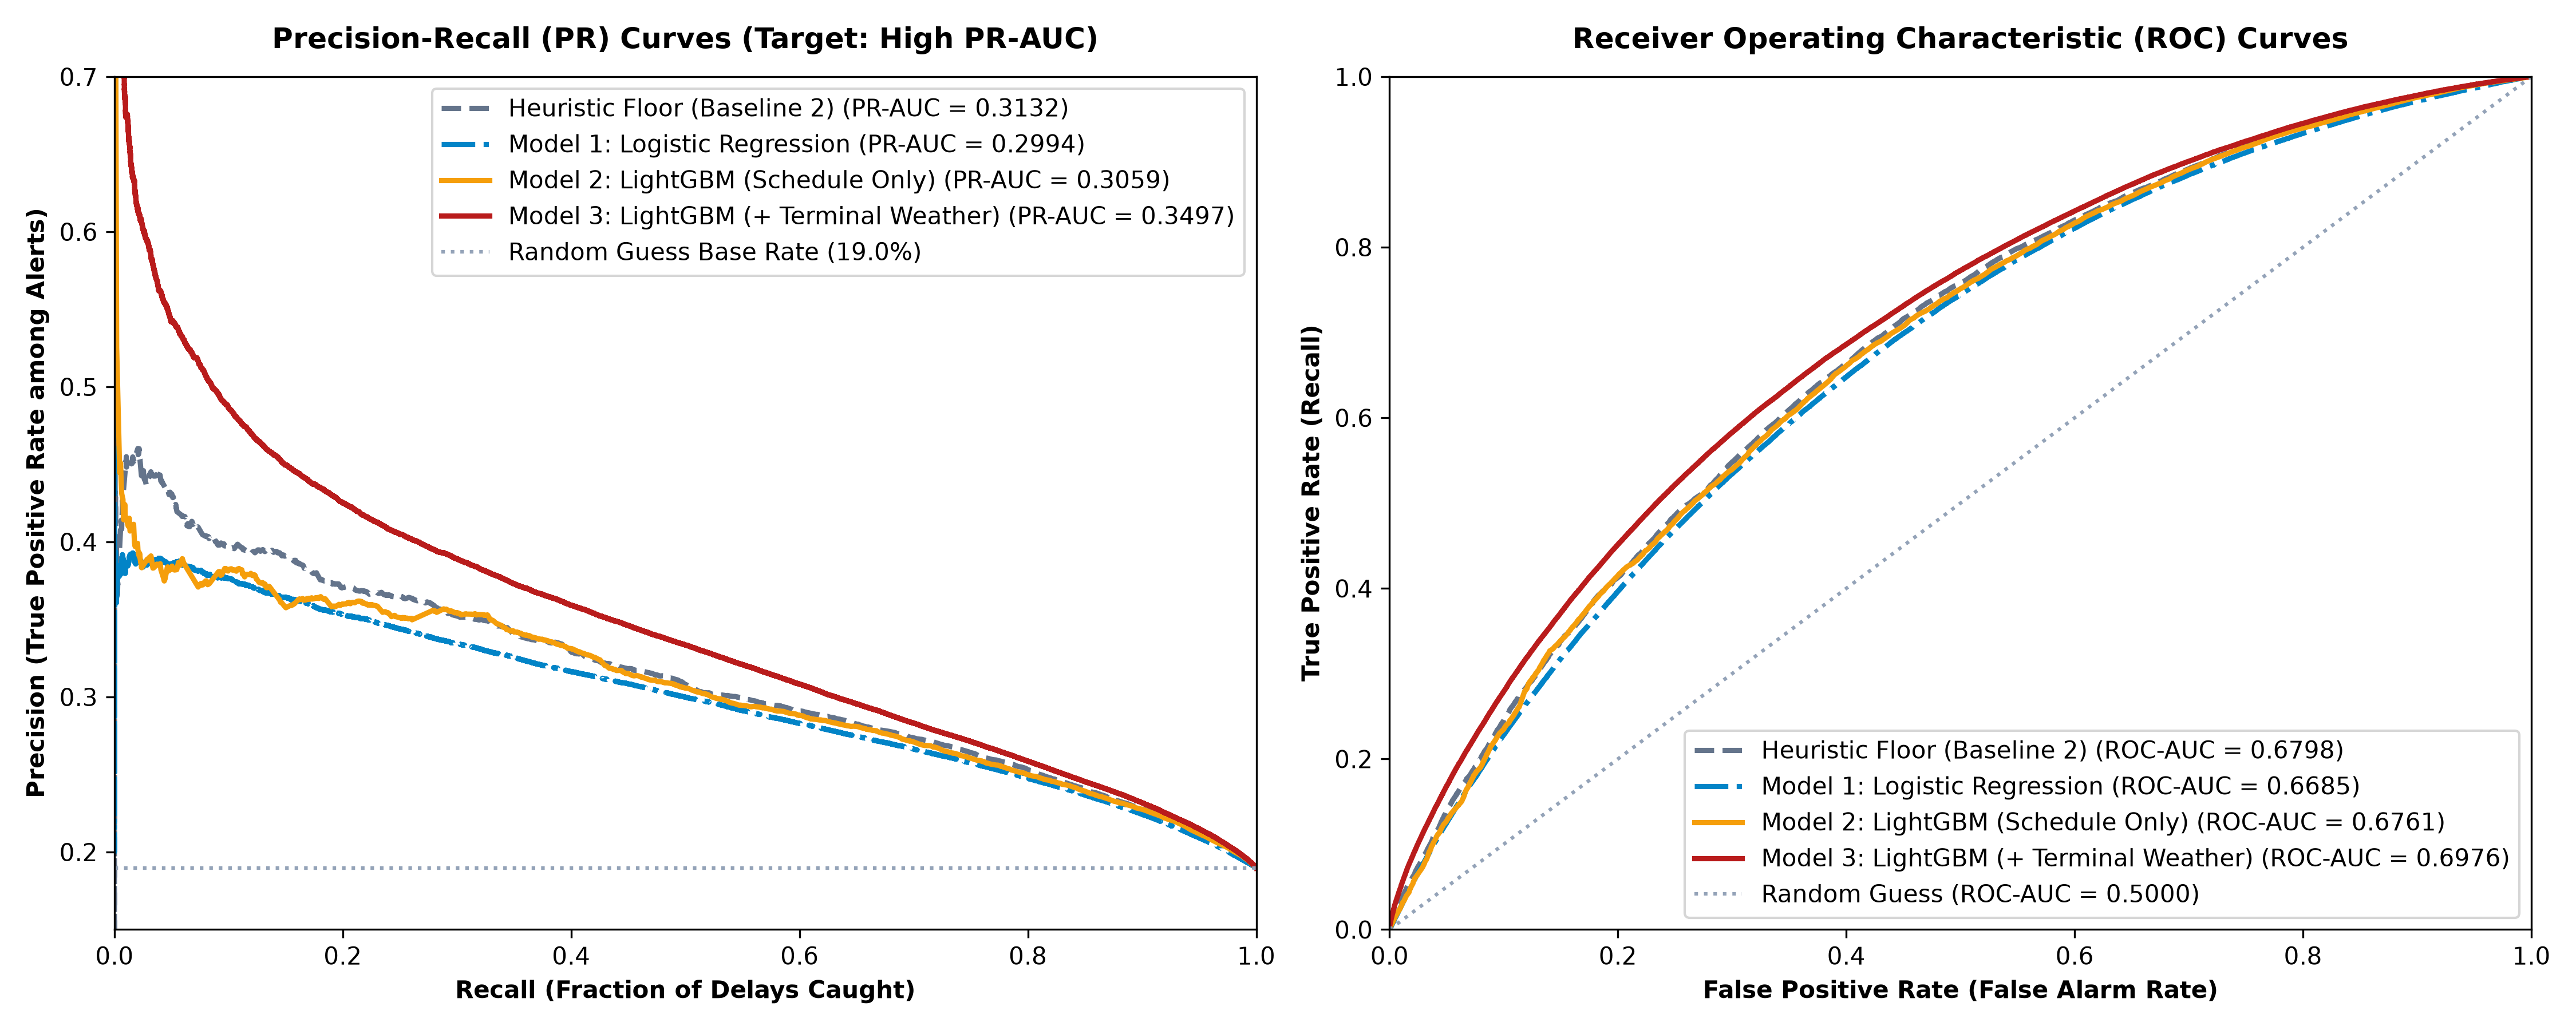

In [ ]:
# Display the pre-rendered publication-grade PR and ROC diagnostic comparison
from IPython.display import Image, display
display(Image(filename="../docs/figures/08_model_pr_roc_comparison.png", width=900))

---
## Chapter 4: What Drives the Winning Model?
### LightGBM Gain Feature Importance Analysis

Which features actually moved the needle?
In LightGBM, **Gain Importance** measures the total improvement in log-loss brought by splits using each feature across all 200 boosting iterations.

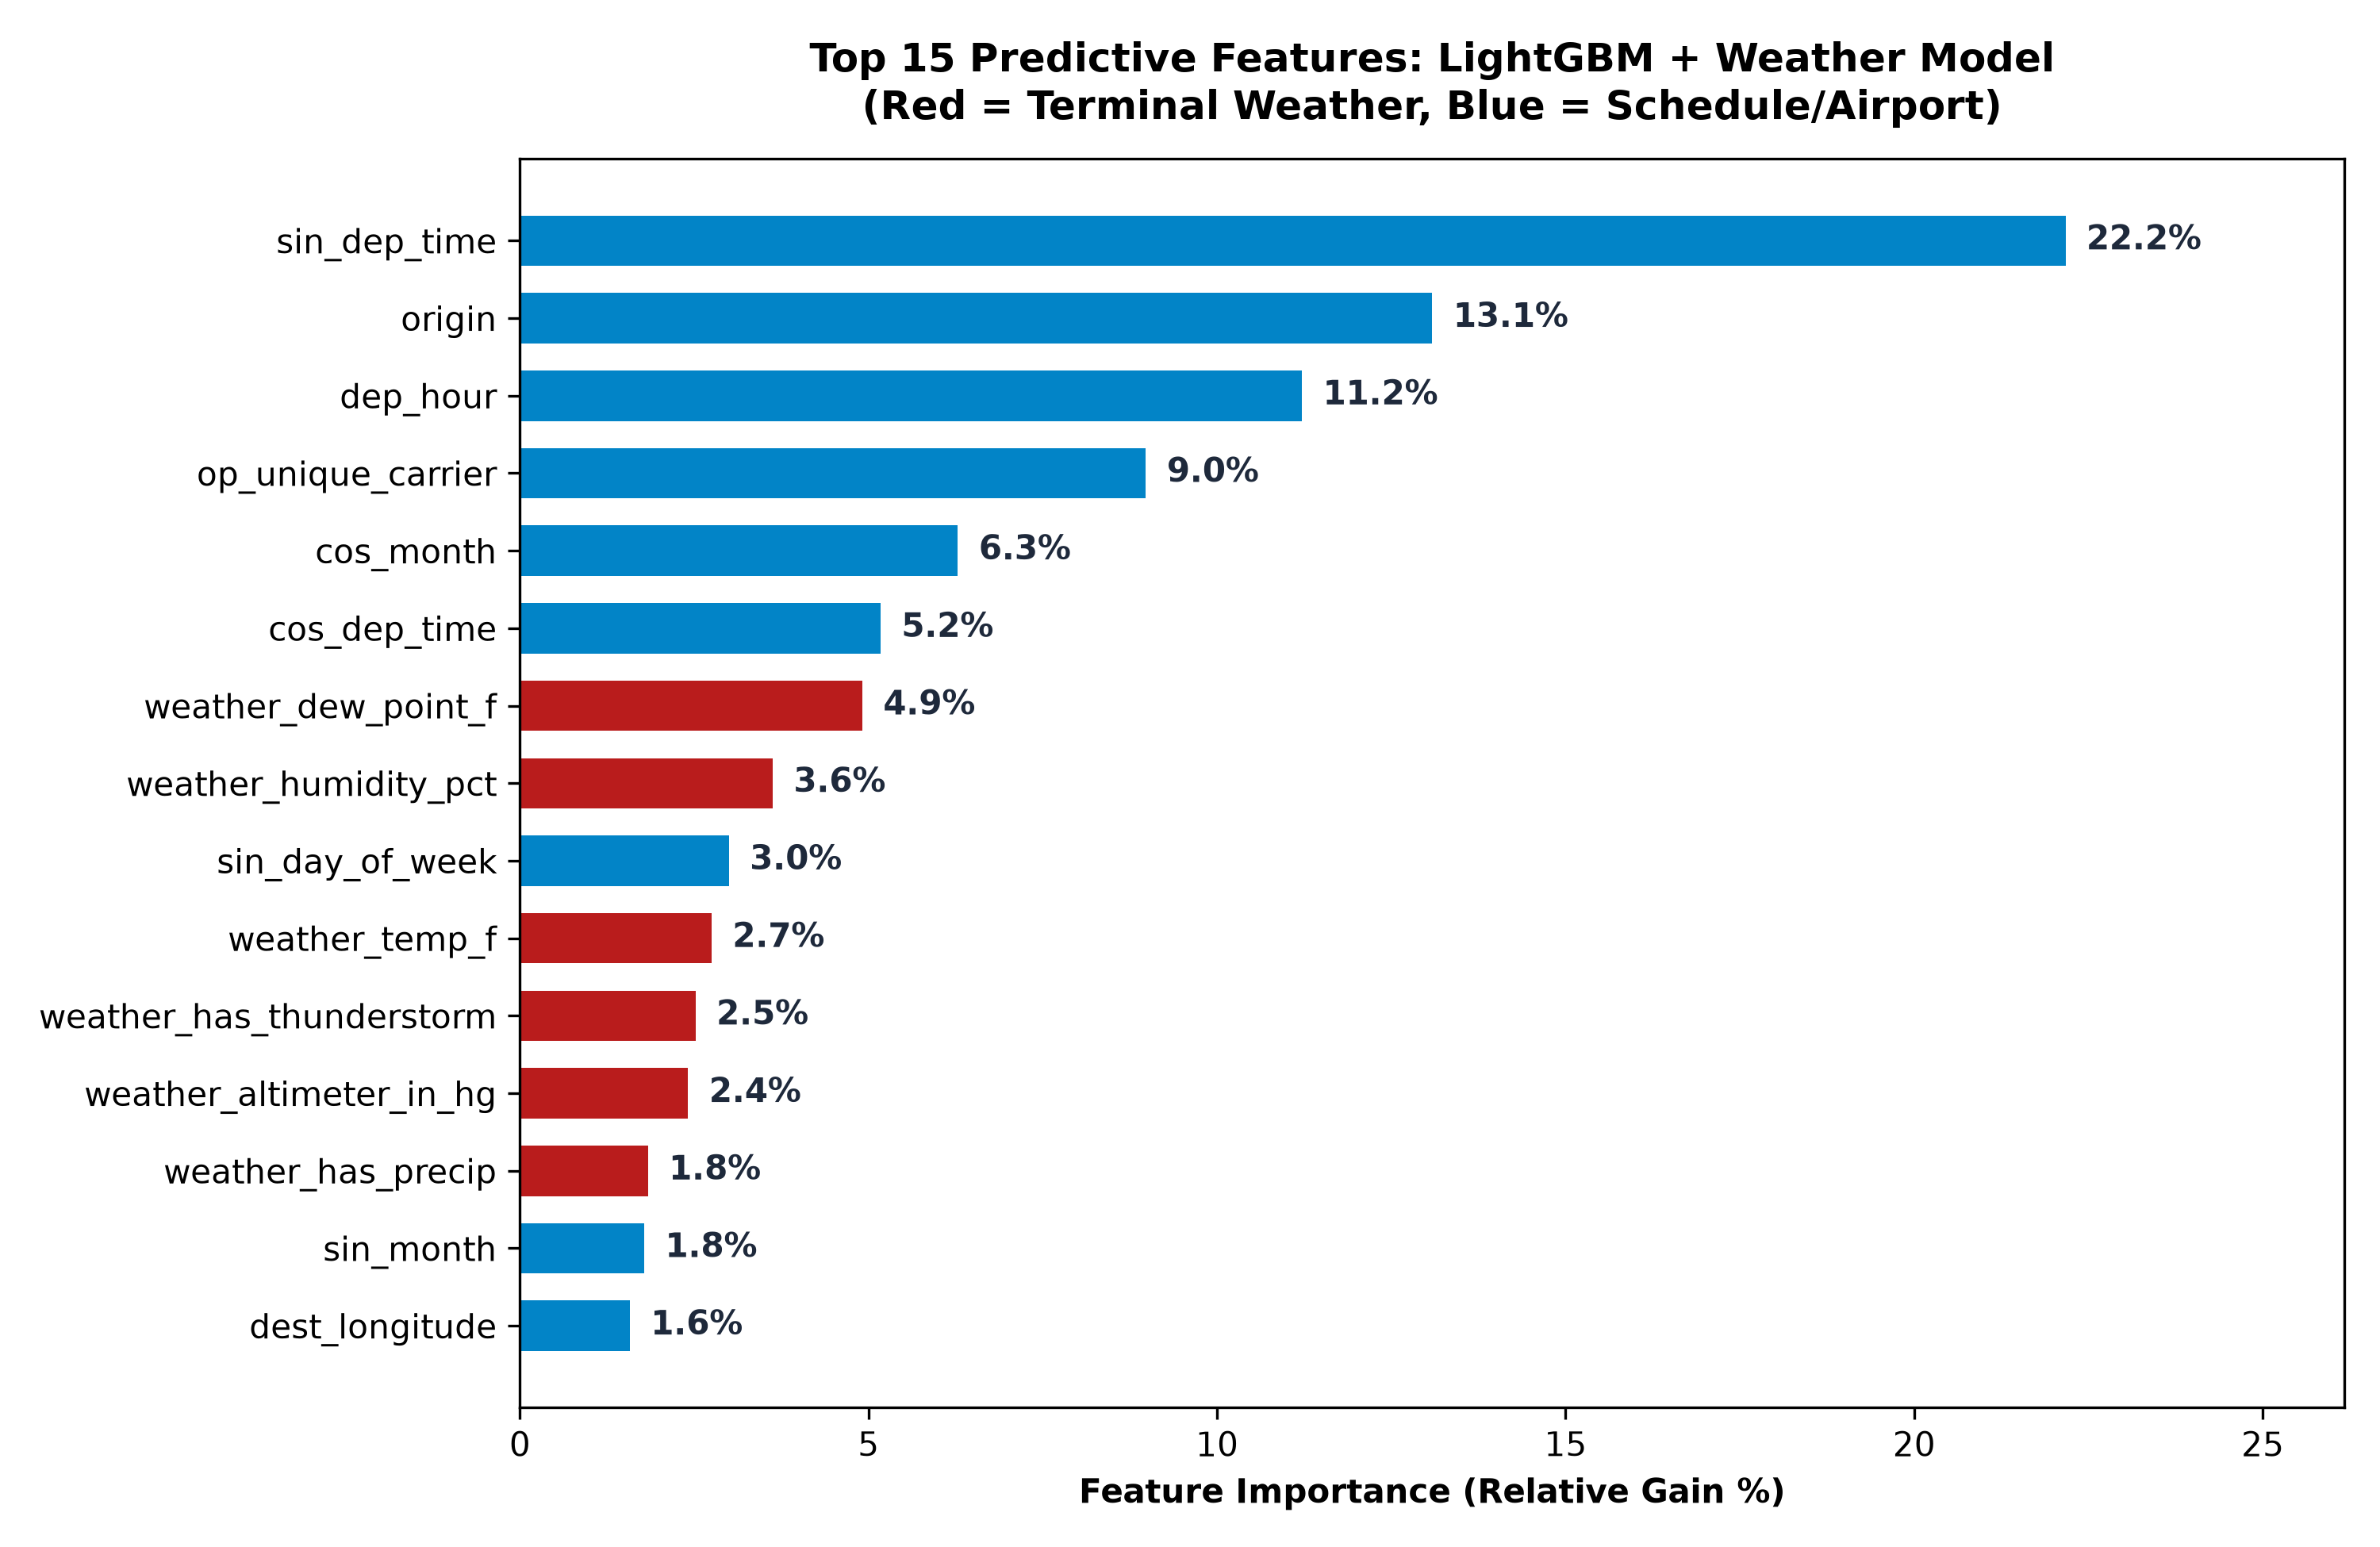

In [ ]:
# Display Top 15 Predictive Features by Relative Gain
display(Image(filename="../docs/figures/09_lightgbm_feature_importance.png", width=800))

---
## Chapter 5: Model Diagnostic Discussion
### Analyzing Metric Benchmarks and Next Steps

---

### Question 1: "Are these scores good? PR-AUC = 0.35 and ROC-AUC = 0.70?"
#### Practical Considerations:
**YES — in fact, they are exceptionally realistic for commercial aviation.
Here is why:
1. **The Base Rate Reality:
In September and October, only **18.97%** of flights were delayed. A random model gets a PR-AUC of **0.1897**.
Our Challenger model achieves **0.3497 PR-AUC** — that is an **84% precision lift over random guessing**!
2. **The 2-Hour Advance Warning Horizon:
Remember: we are predicting **2 hours before scheduled pushback** ($T-2\text{h}$). At $T-2\text{h}$, the passengers haven't even boarded, the inbound plane may still be in the air 50 miles away, and air traffic control (ATC) hasn't issued ground stops yet.
3. **The "0.95 ROC-AUC" Red Flag:
If you ever see a paper or blog post claiming *"We predicted flight delays with 0.95 ROC-AUC"*, **they cheated**. They almost certainly leaked actual taxi-out times, gate departure delays, or post-cutoff radar data. In real-world FAA/commercial systems operating at $T-2\text{h}$, ROC-AUCs between **0.70 and 0.74** are the gold standard.

---

### Question 2: "Should we introduce another algorithm (e.g. CatBoost or XGBoost)?"
#### Practical Considerations:
In school and bootcamps, students think changing algorithms is how you win. In industry, **switching from LightGBM to CatBoost or XGBoost will only yield tiny fluctuations ($\pm 0.003$ PR-AUC)**.
However, here is what is actually done in production:
1. **CatBoost as an Ensemble Partner:
CatBoost uses symmetric oblivious trees and handles high-cardinality categorical features (airports and carriers) with target statistics. Training a CatBoost model and **blending its probabilities 50/50 with LightGBM** often smooths out decision boundaries and improves Brier calibration.
2. **Probability Calibration (Platt Scaling / Isotonic Regression):
Tree models can produce slightly distorted probability peaks near the edges. Post-processing the raw probabilities with a calibrated sigmoid can improve the Brier score.

---

### Question 3: "What should we do to actually increase these metrics?"
#### Practical Considerations:
In real life, **Domain Feature Engineering beats algorithmic tuning 9 times out of 10.
Here are the 4 high-ROI features that real airline operations teams use to push PR-AUC from 0.35 toward 0.45:

1. ** Inbound Aircraft Propagation (The Tail Number Domino Effect):
*Current State:* We only know when this flight is supposed to leave.
*The Upgrade:* Track the physical plane (`tail_num`). Where is it right now? If the aircraft is currently delayed 45 minutes on its inbound leg from Chicago, our flight out of Newark is **100% guaranteed** to be delayed! This is the #1 signal in aviation.
2. **🎯 Destination Airport Weather & Ground Delay Programs (GDPs):
*Current State:* We only check weather at the origin hub.
*The Upgrade:* If you fly from Atlanta to San Francisco, Atlanta can be sunny and 75°F. But if SFO has dense ocean fog, FAA issues a ground delay program holding Atlanta flights on the ramp! Ingesting destination weather and FAA ground stop alerts adds massive signal.
3. **🚦 Rolling Airport Runway Saturation:
Count how many scheduled takeoffs are sharing the same runway in the same 30-minute block (`origin_scheduled_departures_window_30m`). When an airport schedules 60 planes on a runway rated for 40, congestion delays are inevitable.
4. **📅 Carrier Fleet Buffer Capacity:
Delta has massive spare aircraft reserves in Atlanta; Spirit does not in Orlando. Quantifying carrier spare aircraft ratio by hub directly captures turnaround resilience.

---

### Next Step: Test Set Holdout Unlocking
We have fully audited, trained, benchmarked, and understood our models on Train (Jan–Aug) and Validation (Sep–Oct).
We are now ready to lock Model 3 and evaluate on the untouched **Test Set Holdout (November & December 2025 holiday rush)**!